# Lab 09: ABC on a contaminated Hubble diagram

**ASTR 457, Fall 2026, posted Tue Nov 10, due Tue Nov 17 by noon (fork → PR, as always)**

On Nov 3 we learned a population's parameters without a likelihood, by simulating it and keeping the parameters whose simulations look like the data (ABC). Weyant et al. (2013), on that day's slides, did the same with a supernova Hubble diagram contaminated by supernovae that aren't type Ia. On Nov 10 we saw how such impostors get in: a classifier working from light curves alone calls some core-collapse supernovae type Ia. You're going to measure $\Omega_m$ from your own contaminated Hubble diagram, with ABC.

Put your notebook in `submissions/<your netid>/lab09.ipynb` - the data paths below are relative to that folder. It has to run top to bottom from a fresh kernel ("Restart & Run All").

Part 1 is 20%, Part 2 15%, Part 3 40%, Part 4 15%, and the AI-use appendix and verification plan 10%. Quote every number with its unit (if it has one), an error bar, and a sensible number of digits.

In [133]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

NETID = 'ratchev2'   # <-- set this
LAB = '../../labs/09/data/'                              # from submissions/<your netid>/
d = pd.read_csv(LAB + f'{NETID}.csv')                    # columns: z, m_B, sigma_m
z, m, sig_m = d['z'].to_numpy(), d['m_B'].to_numpy(), d['sigma_m'].to_numpy()

## The survey

Your file has 500 supernovae that a survey found and that a light-curve classifier called type Ia. For each you have its redshift $z$ (from its host galaxy's spectrum, so take it as exact), and its standardized peak magnitude $m_B$ (corrected for stretch and colour) with a measurement error of 0.10 mag.

Here is how your sky was made. I generated it, so I know your true values.

- **Cosmology:** flat $\Lambda$CDM with $H_0 = 70$ km/s/Mpc, so the distance modulus is $\mu(z; \Omega_m) = 5 \log_{10}\left(d_L / 10\,{\rm pc}\right)$ with $d_L = (1+z)\,\frac{c}{H_0}\int_0^z \frac{dz'}{\sqrt{\Omega_m (1+z')^3 + 1 - \Omega_m}}$. Your $\Omega_m$ is unknown.
- **Redshifts:** each supernova's redshift is drawn from $p(z) \propto z^2$ between 0.01 and 0.7. (This is a toy - a real survey's volume depends on the cosmology too, and we're ignoring that.)
- **Type Ia:** standardized absolute magnitude $M \sim \mathcal{N}(-19.30, 0.12)$.
- **Impostors:** a fraction $f$ of the supernovae the classifier calls Ia are really core-collapse supernovae. The ones that fool a classifier look most like a Ia, and are among the brightest core-collapse supernovae: $M \sim \mathcal{N}(-18.5, 0.5)$. Your $f$ is unknown.
- **Measurement:** $m_B = M + \mu(z; \Omega_m) + \epsilon$, with $\epsilon \sim \mathcal{N}(0, 0.10)$.

Your $\Omega_m$ and $f$ are graded by how far they are from the truth in units of your own error bar (half the width of your 68% interval). Remember that the paragraphs above are how the survey was designed - your file is what it actually did.

## Part 1: Look first, then write the simulator (20%)

1. Plot your Hubble diagram ($m_B$ against $z$), and your Hubble residuals, $m_B - (-19.30) - \mu(z; 0.3)$, against $z$. Histogram $m_B$. Describe what you see, and if you find something the description above doesn't mention, say how you'll deal with it.
2. Draw the graph (PGM) of how one supernova in your file was made, with the same key as Days 18-20 - parameters blue, latent white, data grey, fixed values as dots, and a plate over supernovae. Which quantities are latent? Where does $f$ enter?
3. Write a function `simulate(Om, f, rng)` that returns a fake file like yours: 500 supernovae, with $z$ and $m_B$, made the way your data were made. Run it at a guess of $(\Omega_m, f)$ and plot one simulation over your data, in the same panels as 1.1.

#### Hints:
- `astropy.cosmology.FlatLambdaCDM(H0=70, Om0=...).distmod(z)` is correct, but far too slow to call 50,000 times. Tabulate $\mu(z; \Omega_m)$ once, on a grid of $z$ and $\Omega_m$ (spacing 0.005 in $\Omega_m$ is plenty), and interpolate. Check your table against astropy at a few points.
- Your simulator will be called tens of thousands of times. Draw everything for one dataset in a few vectorized `numpy` calls, not a Python loop over supernovae.

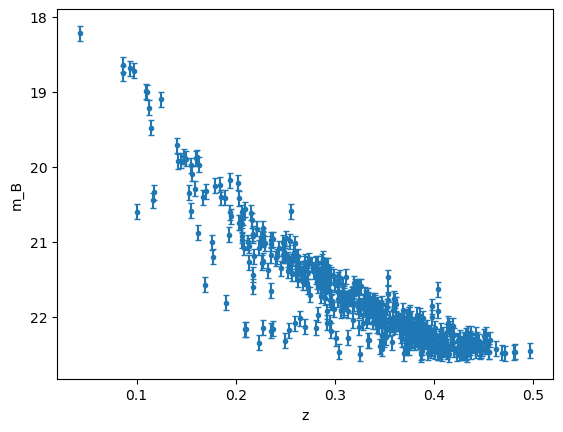

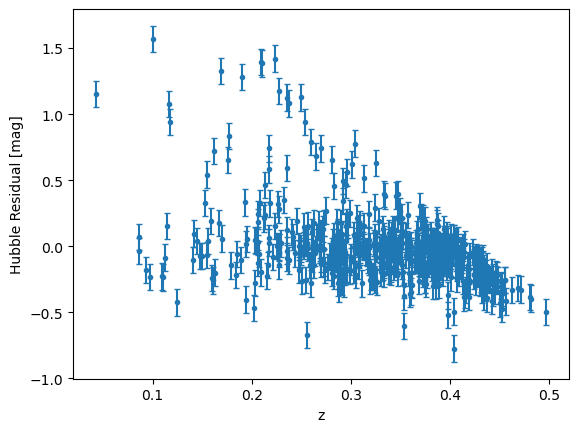

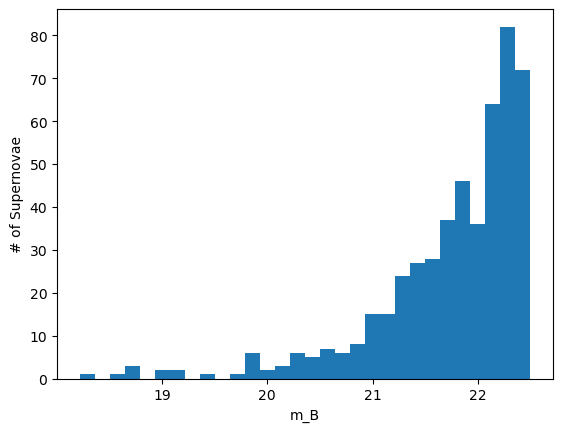

In [134]:
# Part 1: your work here

# 1.
from astropy.cosmology import FlatLambdaCDM
mu = FlatLambdaCDM(H0=70, Om0=0.3).distmod(z).value
residuals = m - (-19.30) - mu

plt.errorbar(z, m, yerr=sig_m, fmt='o', markersize=3, capsize = 2)
plt.xlabel('z')
plt.ylabel('m_B')
plt.gca().invert_yaxis()
plt.show()

plt.errorbar(z, residuals, yerr=sig_m, fmt='o', markersize=3,capsize=2)
plt.xlabel('z')
plt.ylabel('Hubble Residual [mag]')
plt.show()

plt.hist(m, bins=30)
plt.xlabel('m_B')
plt.ylabel('# of Supernovae')
plt.show()

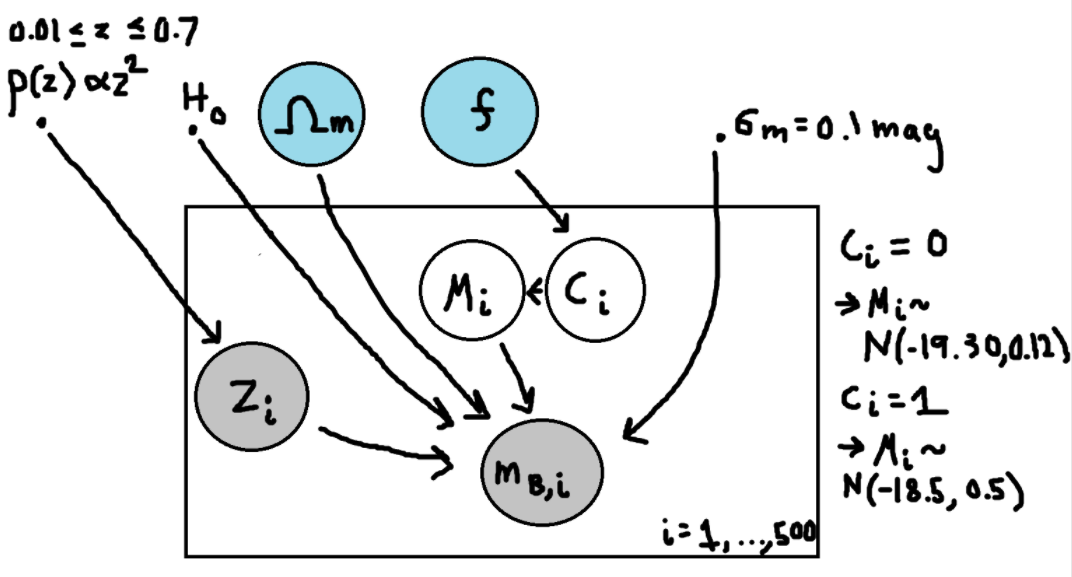

In [135]:
from scipy.interpolate import RegularGridInterpolator
grid_0m = np.arange(0, 2, 0.005)
grid_z = np.arange(0.01, 1.5, 0.0005)
mu_vals = np.zeros((len(grid_0m), len(grid_z)))

for i in range(len(grid_0m)):
    mu_vals[i, :] = FlatLambdaCDM(H0 = 70, Om0 = grid_0m[i]).distmod(grid_z).value
interpolated_mu = RegularGridInterpolator((grid_0m, grid_z), mu_vals)

# checking against astropy for a few points as is recommended by the problem
test_0m = [0.1, 0.2, 0.3, 0.4, 0.5]
test_z = [0.1, 0.2, 0.3, 0.4, 0.5]
for i in range(len(test_0m)):
    interp_val = interpolated_mu([test_0m[i], test_z[i]])[0]
    exact_val = FlatLambdaCDM(H0 = 70, Om0 = test_0m[i]).distmod(test_z[i]).value
    print("0m =", test_0m[i], "z =", test_z[i])
    print("Interp:", interp_val)
    print("Exact:", exact_val)

0m = 0.1 z = 0.1
Interp: 38.34838774454788
Exact: 38.34838774454788
0m = 0.2 z = 0.2
Interp: 39.98909208534501
Exact: 39.98909208534501
0m = 0.3 z = 0.3
Interp: 40.9554600441144
Exact: 40.9554600441144
0m = 0.4 z = 0.4
Interp: 41.62521872607283
Exact: 41.62521872607283
0m = 0.5 z = 0.5
Interp: 42.124330717104534
Exact: 42.12433071710454


In [136]:
def simulate(Om, f, rng):
    M = np.zeros(500)
    z = (0.01**3 + rng.uniform(0, 1, 500) * (0.7 ** 3 - 0.01 ** 3))**(1/3)
    C = rng.binomial(1, f, 500)
    M[C == 0] = rng.normal(-19.3, 0.12, np.sum(C == 0))
    M[C == 1] = rng.normal(-18.5, 0.5, np.sum(C == 1))
    m_B = M + interpolated_mu(np.column_stack((np.full(500, Om), z))) + rng.normal(0, 0.1, 500)
    return z, m_B, 0.1

In [137]:
# Guess of sigma_m = 0.3, f = 0.1
rng = np.random.default_rng(1000)
z_sim, m_sim, sigma_m = simulate(0.3, 0.1, rng)

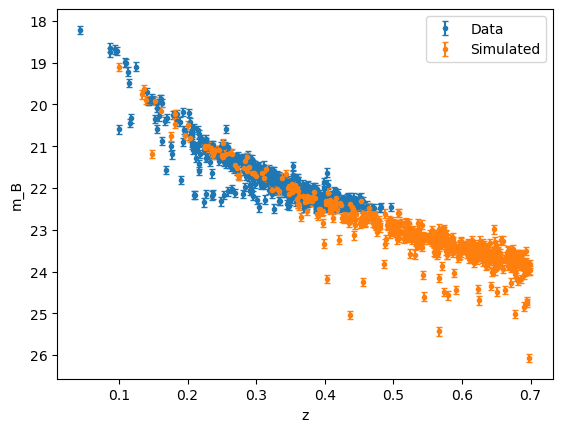

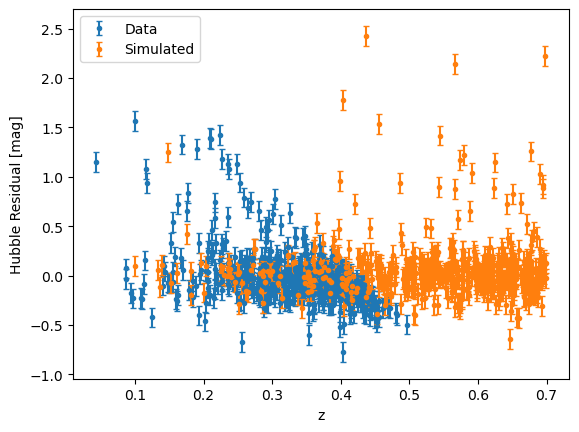

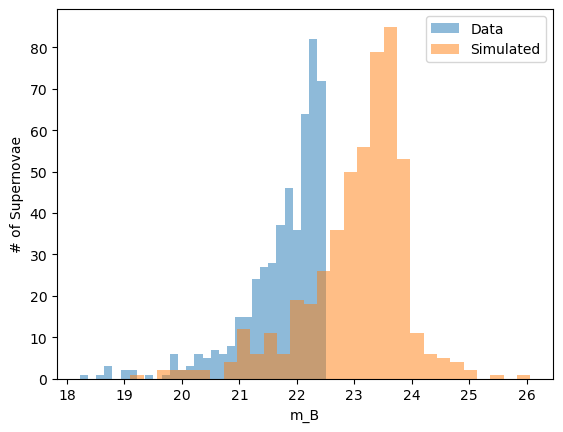

In [138]:
plt.errorbar(z, m, yerr=sig_m, fmt='o', markersize=3, capsize = 2, label = "Data")
plt.errorbar(z_sim, m_sim, yerr = sigma_m, fmt = 'o', markersize = 3, capsize = 2, label = "Simulated")
plt.xlabel('z')
plt.ylabel('m_B')
plt.gca().invert_yaxis()
plt.legend()
plt.show()

mu_sim = interpolated_mu(np.column_stack((np.full(500, 0.3), z_sim)))
res_sim = m_sim - (-19.3) - mu_sim
plt.errorbar(z, residuals, yerr=sig_m, fmt='o', markersize=3,capsize=2, label = "Data")
plt.errorbar(z_sim, res_sim, yerr = sigma_m, fmt = 'o', markersize=3,capsize=2, label = "Simulated")
plt.xlabel('z')
plt.ylabel('Hubble Residual [mag]')
plt.legend()
plt.show()

plt.hist(m, bins=30, label = "Data", alpha = 0.5)
plt.hist(m_sim, bins = 30, label = "Simulated", alpha = 0.5)
plt.xlabel('m_B')
plt.ylabel('# of Supernovae')
plt.legend()
plt.show()

**ANSWER (what you see in the data, your graph, and what your simulator does):**

1. In general the apparent magnitude seems to increase with increasing z as we expect. Even though the relation is for the most part decently tight, there is quite a bit of spread below the main line, which may correspond to the core collapse objects. Meanwhile, most of the Hubble residuals are around zero but there are some objects with quite high residuals. Most of these outliers are positive residuals which are again consistent with the fainter population (-18.5 vs -19.3) associated with the core collapse imposters. There also appears to be some sort of negative trend at high redshifts (though this area is quite small). This may suggest that our cosmology does not hold up at these higher redshifts. The histogram is quite asymmetric with a long tail towards brighter magnitudes. It is hard to infer too much from the histogram in its current form since it combines objects at different redshifts.

2. The true classificiation C_i of each supernova and the absolute magnitude of each supernoa are latent. f enters by determining the number of C_0's and C_1's (1a and core collapse respectively)

## Part 2: The fit you'd do without thinking (15%)

1. Pretend every supernova in your file is a type Ia. Fit $\Omega_m$ by minimizing $\chi^2 = \sum_i [m_{B,i} - (-19.30) - \mu(z_i; \Omega_m)]^2 / \sigma_{\rm tot}^2$, with $\sigma_{\rm tot}^2 = 0.12^2 + 0.10^2$, and report $\hat\Omega_m$ with its $1\sigma$ error from $\Delta\chi^2 = 1$.
2. Which way should the impostors push this fit, and why? Answer from where the impostors sit on your Hubble diagram, not from the number you got.

In [139]:
# Part 2: your work here
from scipy.optimize import minimize
def chi2(Om):
    mu = interpolated_mu(np.column_stack((np.full(500, Om), z)))
    return np.sum((m - (-19.3) - mu)**2 / (0.12**2 + 0.1**2))
def chi2_minimize(x):
    return chi2(x[0])
result = minimize(chi2_minimize, x0 = [0.3], bounds = [(0.01, 1.0)])
Om_best = result.x[0]
chi2_min = result.fun
Om_vals = np.linspace(0.05, 1.0, 10000)
chi2_vals = np.array([chi2(Om) for Om in Om_vals])
Om_low = Om_vals[Om_vals < Om_best][np.argmin(np.abs(chi2_vals[Om_vals < Om_best] - (chi2_min + 1)))]
Om_high = Om_vals[Om_vals > Om_best][np.argmin(np.abs(chi2_vals[Om_vals > Om_best] - (chi2_min + 1)))]
print("Omega_m hat =", round(Om_best, 3), "+", round(Om_high - Om_best, 3), "/ -", round(Om_best - Om_low, 3))

Omega_m hat = 0.368 + 0.014 / - 0.014


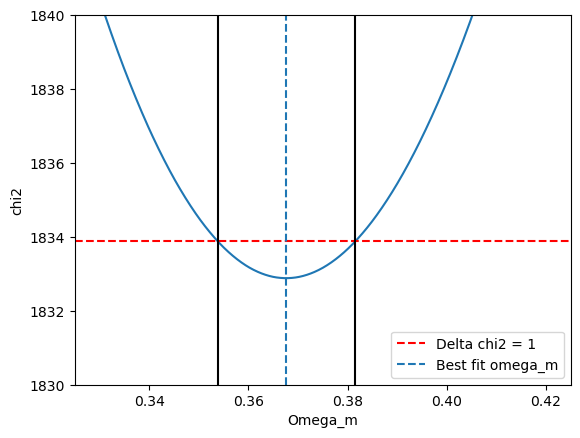

In [140]:
plt.figure()
plt.plot(Om_vals, chi2_vals)
plt.axhline(chi2_min + 1, color='red', linestyle='--', label='Delta chi2 = 1')
plt.axvline(Om_best, linestyle='--',
            label='Best fit omega_m')
plt.axvline(Om_low, color='black')
plt.axvline(Om_high, color='black')
plt.xlabel('Omega_m')
plt.ylabel('chi2')
plt.legend()
plt.xlim(0.325, 0.425)
plt.ylim(1830, 1840)
plt.show()

**ANSWER (the naive fit, then why the impostors push it the way they do):**

The imposters should push the fitted Omega_m lower because on the Hubble diagram we can see that they sit below the 1a trend (due to axes limits this means they are fainter as higher magnitudes are going down). This means that the fit is interpreting these fainter imposters as being farther away type 1a supernova. This "farther" seeming population is predicted by a lower Omega_m and so the bias pushes the fit to lower Omega_m.

## Part 3: ABC (40%)

1. **Summaries.** Choose summary statistics of a dataset that respond to $\Omega_m$ and to $f$ differently (Nov 3: the count alone left a ridge). For each, say which parameter you expect it to track and why. Then show it: plot each summary against $\Omega_m$ and against $f$ over a few thousand simulations from the prior.
2. **Rejection ABC.** Use flat priors, $\Omega_m \in [0.05, 0.7]$ and $f \in [0, 0.5]$. Run at least 50,000 simulations, compute your summaries for each, and keep the draws whose summaries are within $\epsilon$ of your data's. Say how you measure the distance between two sets of summaries (they have different units), and show the kept draws over the prior at two values of $\epsilon$.
3. Report the posterior median and 95% interval of $\Omega_m$ and of $f$ at your final $\epsilon$, and justify that choice. Compare $\Omega_m$ with your Part 2 fit.

#### Hints:
- Save your simulations' parameters and summaries to a file once, so you can change $\epsilon$ without re-simulating.
- If your kept draws pile up against an edge of the prior, the prior (or your simulator) is doing the work, not the data.

In [141]:
# Part 3: your work here

# using median residual and standard deviation of the residuals
mu_ref = interpolated_mu(np.column_stack((np.full(500, 0.3), z)))
res = m - (-19.3) - mu_ref
median_res = np.median(res)
std_res = np.std(res)

In [97]:
rng = np.random.default_rng(10)
N = 3000

Om_sim_vals = rng.uniform(0.05, 0.7, N)
f_sim_vals = rng.uniform(0, 0.5, N)

median_sims = np.zeros(N)
std_sims = np.zeros(N)

for i in range(N):
    z_sim, m_sim, err = simulate(Om_sim_vals[i], f_sim_vals[i], rng)
    mu_ref_sim = interpolated_mu(np.column_stack((np.full(len(z_sim), 0.3), z_sim)))
    residuals_sim = m_sim - (-19.3) - mu_ref_sim
    median_sims[i] = np.median(residuals_sim)
    std_sims[i] = np.std(residuals_sim)

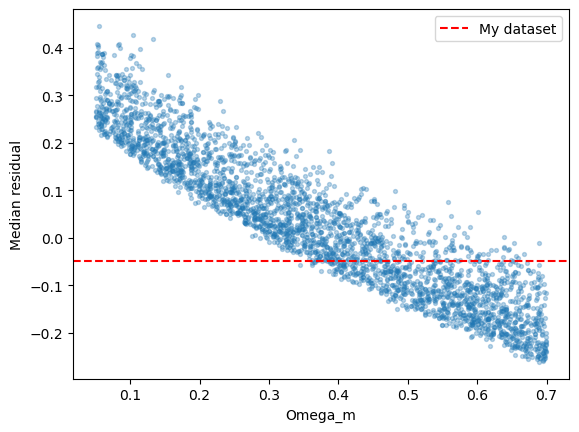

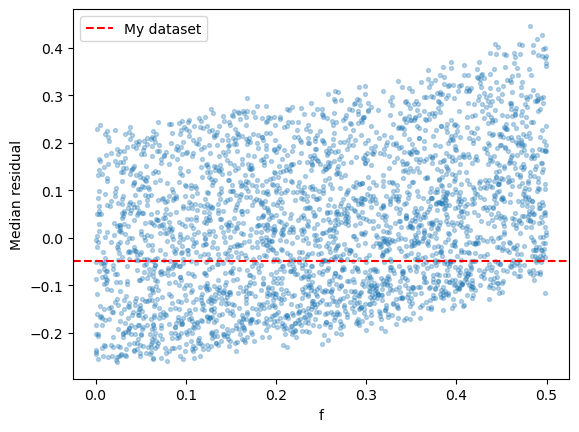

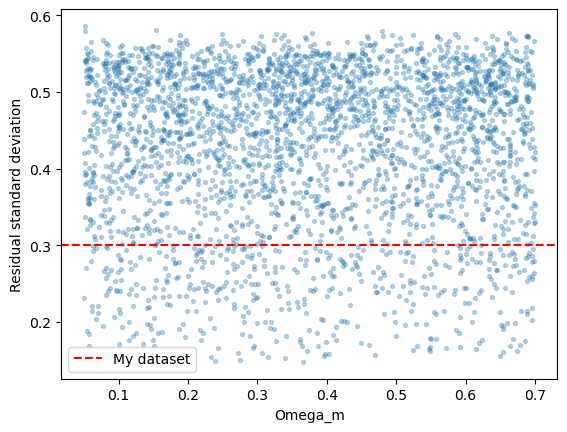

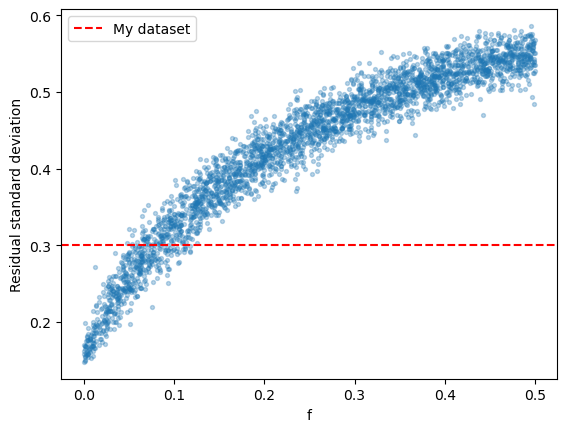

In [98]:
plt.scatter(Om_sim_vals, median_sims, s=8, alpha=0.3)
plt.axhline(median_res, color='red', linestyle='--', label='My dataset')
plt.xlabel('Omega_m')
plt.ylabel('Median residual')
plt.legend()
plt.show()

plt.scatter(f_sim_vals, median_sims, s=8, alpha=0.3)
plt.axhline(median_res, color='red', linestyle='--', label='My dataset')
plt.xlabel('f')
plt.ylabel('Median residual')
plt.legend()
plt.show()

plt.scatter(Om_sim_vals, std_sims, s=8, alpha=0.3)
plt.axhline(std_res, color='red', linestyle='--', label='My dataset')
plt.xlabel('Omega_m')
plt.ylabel('Residual standard deviation')
plt.legend()
plt.show()

plt.scatter(f_sim_vals, std_sims, s=8, alpha=0.3)
plt.axhline(std_res, color='red', linestyle='--', label='My dataset')
plt.xlabel('f')
plt.ylabel('Residual standard deviation')
plt.legend()
plt.show()

In [99]:
N = 100000
rng = np.random.default_rng(13)

Om_sim_vals = rng.uniform(0.05, 0.7, N)
f_sim_vals = rng.uniform(0, 0.5, N)

median_sims = np.zeros(N)
std_sims = np.zeros(N)

for i in range(N):
    z_sim, m_sim, err = simulate(Om_sim_vals[i], f_sim_vals[i], rng)
    mu_ref_sim = interpolated_mu(np.column_stack((np.full(len(z_sim), 0.3), z_sim)))
    residuals_sim = m_sim - (-19.3) - mu_ref_sim
    median_sims[i] = np.median(residuals_sim)
    std_sims[i] = np.std(residuals_sim)

In [100]:
distance = np.sqrt(((median_sims - median_res) / np.std(median_sims))**2 +((std_sims - std_res) / np.std(std_sims))**2)
epsilon_3 = np.percentile(distance, 3)
epsilon_05 = np.percentile(distance, 0.5)
print("3% kept epsilon:", round(epsilon_3, 4))
print("0.5% kept epsilon:", round(epsilon_05, 4))

3% kept epsilon: 0.4217
0.5% kept epsilon: 0.1779


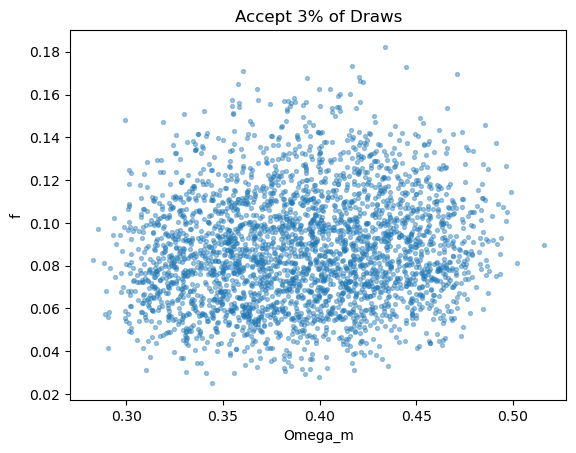

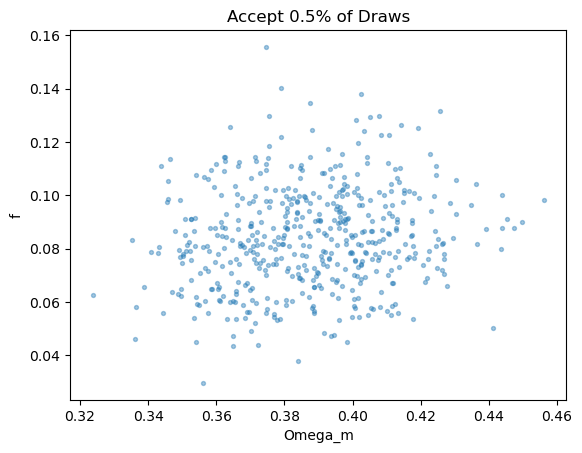

In [101]:
plt.scatter(Om_sim_vals[distance <= epsilon_3], f_sim_vals[distance <= epsilon_3], s=8, alpha=0.4)
plt.xlabel('Omega_m')
plt.ylabel('f')
plt.title('Accept 3% of Draws')
plt.show()

plt.scatter(Om_sim_vals[distance <= epsilon_05], f_sim_vals[distance <= epsilon_05], s=8, alpha=0.4)
plt.xlabel('Omega_m')
plt.ylabel('f')
plt.title('Accept 0.5% of Draws')
plt.show()

In [102]:
Om_median = np.median(Om_sim_vals[distance <= epsilon_05])
Om_interval = np.percentile(Om_sim_vals[distance <= epsilon_05], [2.5, 97.5])

f_median = np.median(f_sim_vals[distance <= epsilon_05])
f_interval = np.percentile(f_sim_vals[distance <= epsilon_05], [2.5, 97.5])

print("Omega_m =", round(Om_median, 4), "+", round(Om_interval[1] - Om_median, 4), "/ -", round(Om_median - Om_interval[0], 4))
print("f =", round(f_median, 4), "+", round(f_interval[1] - f_median, 4), "/ -", round(f_median - f_interval[0], 4))

Omega_m = 0.3875 + 0.0429 / - 0.0413
f = 0.0831 + 0.0412 / - 0.0319


**ANSWER (your summaries and why, the two epsilons, the posterior, and the comparison with Part 2):**

1. I chose the median residual and the standard deviation of the residuals as my summary statistics. The median residual primarily tracks Omega_m because changing the cosmology shifts the predicted distance modulus and therefore the typical residual. It is not very sensitive to f because the median is mostly robust to the fainter imposters, but this falls apart a bit at higher redshift as seen in my plot. The standard deviation of the residual primarily tracks f since increasing the imposter fraction adds more scatter to their broader absolute-magnitude distribution, while changing the cosmology does not impact this.

2. The distance was measured using the Euclidean distance wwhere the median and standard deviation were both scaled by subtracting the observed value in our dataset and dividing by the standard deviation of the summaries across all simulations to make sure we kept a consistent scale and didnt bias towards one summary.

3. I chose epsilon = 0.1779 which accepts 0.5% of the simulations. This is more selective than the 3% threshold and by using 100k draws this corresponds to 500 accepted draws which is a reasonable amount to calculat the 95% interval without including more than necessary. The obtained posterior median is 0.3875 which is close but larger than the 0.368 value obtained in part 2. We expected it to be larger because of the downward bias of the naive fit caused by contamination of fainter core-collapse supernova. It is in fact larger as we expect, however the value from part 2 is within the 95% interval of the simulation value. This may simply be due to the fact that f is quite small (median of 8.31%) and so this bias is not large enough to make the naive fit outside of this interval.

## Part 4: Check it (15%)

1. **Posterior predictive check.** For 100 of your kept draws, simulate a new dataset. Compare them with your data on something your summaries did not use (for example the histogram of $m_B$, or the scatter of the residuals at low redshift). Do your data look like a typical simulation?
2. **Coverage.** Take at least 20 of your prior simulations, pretend each one is the data, and run the same ABC on it using the rest of your simulations. How often does your 95% interval contain the true $\Omega_m$, and the true $f$? (Nov 3: a 95% interval should hold the truth 95% of the time.)
3. **What does your simulator assume?** Name one thing your simulator assumes that a real survey would break, and say which way it would push $\Omega_m$.

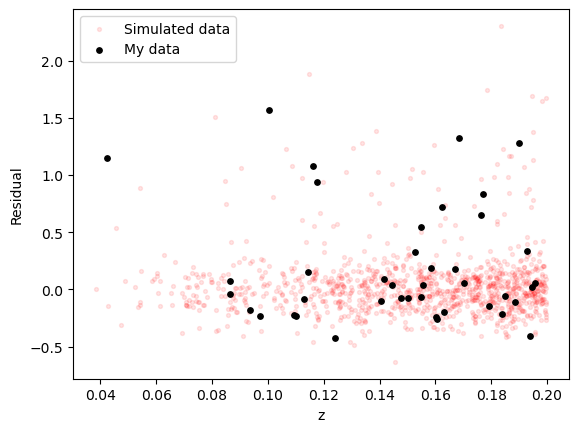

In [112]:
# Part 4: your work here
rng = np.random.default_rng(1313)
i_pred = rng.choice(np.where(distance <= epsilon_05)[0], 100, replace=False)



for j,i in enumerate(i_pred):
    if (j == 0):
        z_sim, m_sim, err = simulate(Om_sim_vals[i], f_sim_vals[i], rng)
        residuals_sim = m_sim - (-19.3) - interpolated_mu(np.column_stack((np.full(len(z_sim), 0.3), z_sim)))
        plt.scatter(z_sim[z_sim < 0.2], residuals_sim[z_sim < 0.2], color = 'red', s = 8, alpha = 0.1, label = "Simulated data")
    else:
        z_sim, m_sim, err = simulate(Om_sim_vals[i], f_sim_vals[i], rng)
        residuals_sim = m_sim - (-19.3) - interpolated_mu(np.column_stack((np.full(len(z_sim), 0.3), z_sim)))
        plt.scatter(z_sim[z_sim < 0.2], residuals_sim[z_sim < 0.2], color = 'red', s = 8, alpha = 0.1)

residuals_obs = m - (-19.3) -  interpolated_mu(np.column_stack((np.full(len(z), 0.3), z)))
plt.scatter(z[z < 0.2], residuals_obs[z < 0.2], color='black', s=15, label='My data')

plt.xlabel('z')
plt.ylabel('Residual')
plt.legend()
plt.show()

In [122]:
rng = np.random.default_rng(1717)
idx = rng.choice(N, 5000, replace = False)
other_idx = np.ones(N, dtype = bool)
other_idx[idx] = 0
Om_count = 0
f_count = 0

for i in idx:
    median_choice = median_sims[i]
    std_choice = std_sims[i]
    dist_choice = np.sqrt(((median_sims[other_idx] - median_choice) / (np.std(median_sims[other_idx])))**2 + ((std_sims[other_idx] - std_choice) / (np.std(std_sims[other_idx])))**2)

    epsilon = np.percentile(dist_choice, 0.5)
    Om_interval = np.percentile(Om_sim_vals[other_idx][dist_choice <= epsilon], [2.5, 97.5])
    f_interval = np.percentile(f_sim_vals[other_idx][dist_choice <= epsilon], [2.5, 97.5])

    if ((Om_interval[0] <= Om_sim_vals[i]) and (Om_sim_vals[i] <= Om_interval[1])):
        Om_count += 1
    if ((f_interval[0] <= f_sim_vals[i]) and (f_sim_vals[i] <= f_interval[1])):
        f_count += 1 

print("Coverage of 95% interval for Omega_m:", Om_count / 5000)
print("Coverage of 95% interval for f:", f_count / 5000)

Coverage of 95% interval for Omega_m: 0.9734
Coverage of 95% interval for f: 0.9572


**ANSWER (the check, the coverage, and the assumption):**

1. In the posterior predictive check, we can see that our data does look very simular to a typical simulation. Most of the residuals hover around 0 with some larger positive residuals in both cases.

2. The coverage is close to the expected 95% for both parameters, which suggests that the ABC intervals are well calibrated. However, Omega_m has a slightly higher coverage than 95% (97.3%) which means that the intervals for it may be slightly conservative.

3. One assumption of our simulator is that this contamination fraction f is the same at every redshift. This is not necessarily true in reality, and if this fraction varies with redshift we would need to account for that. For example, if the contamination fraction increases at higher redshift, there would be extra faint objects that would bias the Omega_m fit even further downward.

## Part 5: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 3 numbers, and what failure would have looked like for each. Part 4.2 is already one. Another to consider: simulate a dataset at an $(\Omega_m, f)$ you choose, run your whole ABC on it, and see whether you get back what you put in.

**AI-USE APPENDIX:**

I didn't use AI although I did have to google how to interpolate with a grid and through that found the documentation for scipy's RegularGridInterpolator

**REFLECTION:**

I didn't use AI, so this is not applicable.

**VERIFICATION PLAN:**

Perhaps the most important of the checks that I did before trusting Part 3 was checking for multiple different summary statistics which ones acted separately with Omega_m and f the most. I initially used the mean but found that the median was a better separate measure and so went back to change this. The plots were very helpful in this regard as we can visually see how coupled these dependencies are. A failure would have been if both summary statistics responded or didn't respond to changes in Omega_m, rather than each summary statistic strongly responding to one of Omega_m or f. Another check I did before choosing an epsilon value was to try out a lot of different values and slowly shrink the amount of draws accepted until the "cloud" of points stopped shrinking by sizable margins in the Omega_m and f axis. I made sure that the epsilon that I chose had enough accepted draws while also being at the point where the range of Omega_m and f values is no longer falling considerably. A failure here would have been if the epsilon I chose kept too small of an amount of points to draw an interval from or was at a place where decreasing epsilon could still susbtantially decrease the width of the accepted draws in the parameter space. I also simulate a dataset below at some parameters, run my ABC, and see if the interval contains the known parameters. A failure here would be the interval not containing the values I used to generate the data set.

In [132]:
rng = np.random.default_rng(3333)
Om_true = 0.5
f_true = 0.15
z_verify, m_verify, err = simulate(Om_true, f_true, rng)
mu_verify = interpolated_mu(np.column_stack((np.full(len(z_verify), 0.3), z_verify)))
res_verify = m_verify - (-19.3) - mu_verify

median_verify = np.median(res_verify)
std_verify  = np.std(res_verify)
dist_verify= np.sqrt(((median_sims - median_verify) / np.std(median_sims))**2 +((std_sims - std_verify) / np.std(std_sims))**2)
epsilon_verify = np.percentile(dist_verify, 0.5)

Om_interval_verify = np.percentile(Om_sim_vals[dist_verify <= epsilon_verify], [2.5, 97.5])
f_interval_verify = np.percentile(f_sim_vals[dist_verify <= epsilon_verify], [2.5, 97.5])

print("True Omega_m:", Om_true)
print("True f:", f_true)
print("Omega_m interval:", Om_interval_verify)
print("f interval:", f_interval_verify)

True Omega_m: 0.5
True f: 0.15
Omega_m interval: [0.43763582 0.52913822]
f interval: [0.07169836 0.15845499]
